In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df=pd.read_excel('/content/Bookings-100000-Rows.xlsx')

In [ ]:
df.head()

,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle Images
0,2024-07-26 14:00:00,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/14183/1...
1,2024-07-25 22:20:00,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,NaN,NaN,No,NaN,158,Cash,13,4.1,4.0,https://cdn-icons-png.flaticon.com/128/9983/99...
2,2024-07-30 19:59:00,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,NaN,NaN,No,NaN,386,UPI,40,4.2,4.8,https://cdn-icons-png.flaticon.com/128/9983/99...
3,2024-07-22 03:15:00,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,384,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...
4,2024-07-02 09:02:00,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,NaN,NaN,No,NaN,822,Credit Card,45,4.0,3.0,https://cdn-icons-png.flaticon.com/128/3202/32...


In [ ]:
# Replacing text 'null' with actual missing values (NaN)
df.replace("null", np.nan, inplace=True)

print("Null string replaced with NaN values")

Null string replaced with NaN values


In [ ]:
# Converting to datetime formats
df['Date'] = pd.to_datetime(df['Date'])
df['Time'] = pd.to_datetime(df['Time'], errors='coerce').dt.time

print("Date and Time formats converted successfully")

Date and Time formats converted successfully


In [ ]:
# Converting columns to numeric types for analysis
df['Driver_Ratings'] = pd.to_numeric(df['Driver_Ratings'])
df['Customer_Rating'] = pd.to_numeric(df['Customer_Rating'])
df['Booking_Value'] = pd.to_numeric(df['Booking_Value'])
df['Ride_Distance'] = pd.to_numeric(df['Ride_Distance'])

print("Ratings and Values converted to numeric type")

Ratings and Values converted to numeric type


In [ ]:
# Saving the cleaned data into a new CSV file
df.to_csv("cleaned_ride_bookings.csv", index=False)

print("Cleaned file saved as 'cleaned_ride_bookings.csv'")

Cleaned file saved as 'cleaned_ride_bookings.csv'


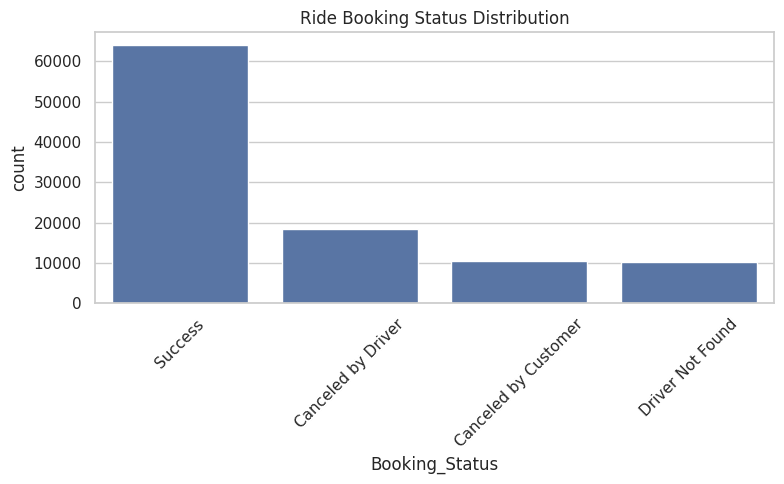

In [ ]:
# 1. Ride Status Distribution
plt.figure(figsize=(8,5))
sns.set_theme(style="whitegrid")
sns.countplot(data=df, x='Booking_Status', order=df['Booking_Status'].value_counts().index)
plt.title('Ride Booking Status Distribution')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('booking_status.png')
plt.show()


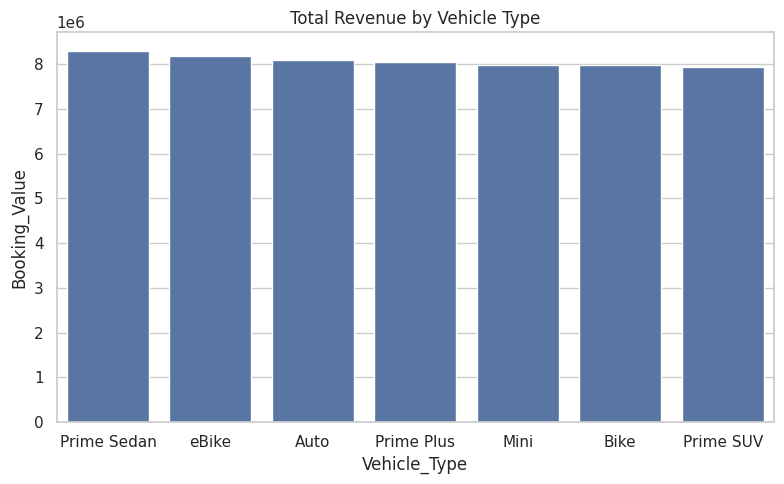

In [ ]:
# 2. Revenue by Vehicle Type
plt.figure(figsize=(8,5))
sns.set_theme(style="whitegrid")
revenue = df.groupby('Vehicle_Type')['Booking_Value'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=revenue, x='Vehicle_Type', y='Booking_Value')
plt.title('Total Revenue by Vehicle Type')
plt.tight_layout()
plt.savefig('revenue_by_vehicle.png')
plt.show()